# Player bounding

Load 20 frames from a SportsMOT training sequence for player-detection work.

In [84]:
from io import BytesIO
from pathlib import Path
import tarfile

from PIL import Image

archive_candidates = [
    Path("data/sportsmot_download/dataset/train.tar"),
    Path("../data/sportsmot_download/dataset/train.tar"),
]
archive = next((path for path in archive_candidates if path.exists()), None)

if archive is None:
    raise FileNotFoundError("Could not find data/sportsmot_download/dataset/train.tar")

sequence = "train/v_-6Os86HzwCs_c001"

with tarfile.open(archive, "r") as tar:
    selected = sorted(
        (member for member in tar.getmembers()
         if member.isfile()
         and member.name.startswith(sequence + "/img1/")
         and member.name.endswith(".jpg")
         and not member.name.rsplit("/", 1)[-1].startswith("._")),
        key=lambda member: member.name,
    )[:20]

    images = [
        Image.open(BytesIO(tar.extractfile(member).read())).convert("RGB")
        for member in selected
    ]

print(f"Loaded {len(images)} frames from {sequence}")
print(f"First frame: {selected[0].name}")

Loaded 20 frames from train/v_-6Os86HzwCs_c001
First frame: train/v_-6Os86HzwCs_c001/img1/000001.jpg


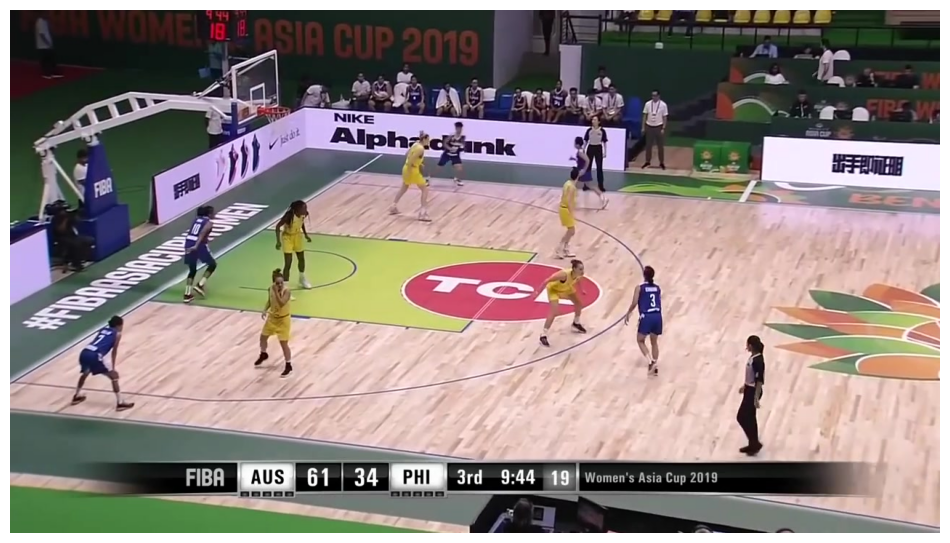

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
plt.imshow(images[0])
plt.axis("off")
plt.show()

### Load Ground Truth
The GT file uses MOT format, one row per player per frame: `frame, track_id, x, y, width, height, conf, class, visibility`. Frames are 1-indexed and `(x, y)` is the top-left corner.

In [86]:
import io
import tarfile
import numpy as np

sequence = "train/v_-6Os86HzwCs_c001"

with tarfile.open(archive, "r") as tar:
    gt_bytes = tar.extractfile(f"{sequence}/gt/gt.txt").read()

gt = np.loadtxt(io.BytesIO(gt_bytes), delimiter=",")

### Load Models
Loading multiple ultralytics models to compare results. YOLO11 (nano, small, medium, large, xlarge) and RT-DETR-x are pretrained on COCO, where class 0 is person.

In [ ]:
%pip install ultralytics

In [88]:
from pathlib import Path
from ultralytics import YOLO, RTDETR

# Create the subfolder for model weights
weights_dir = Path("player_bounding_models")
weights_dir.mkdir(exist_ok=True)

models = {
  "yolo11_nano": YOLO(weights_dir / "yolo11n.pt"),
  "yolo11_small": YOLO(weights_dir / "yolo11s.pt"),
  "yolo11_med": YOLO(weights_dir / "yolo11m.pt"),
  "yolo11_large": YOLO(weights_dir / "yolo11l.pt"),
  "yolo11_xlarge": YOLO(weights_dir / "yolo11x.pt"),
  "rtdetr": RTDETR(weights_dir / "rtdetr-x.pt")
}

### First Frame Check 
Run model predictions on first frame and draw bounding boxes for predictions and gt to visually compare. Red boxes are ground truth. Green boxes are model predictions. Only class 0 (person) predictions are drawn.


0: 384x640 9 persons, 13.1ms
Speed: 1.4ms preprocess, 13.1ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 12 persons, 10.9ms
Speed: 1.2ms preprocess, 10.9ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 11 persons, 14.0ms
Speed: 1.0ms preprocess, 14.0ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 11 persons, 20.5ms
Speed: 1.0ms preprocess, 20.5ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 10 persons, 21.4ms
Speed: 1.0ms preprocess, 21.4ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 640x640 13 persons, 3 chairs, 68.0ms
Speed: 2.6ms preprocess, 68.0ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)


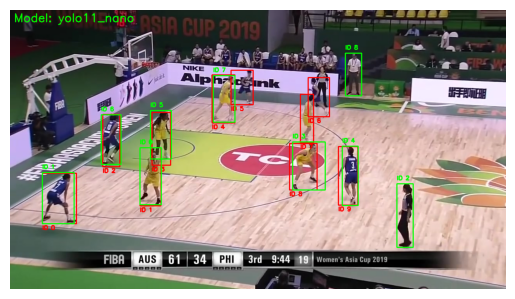

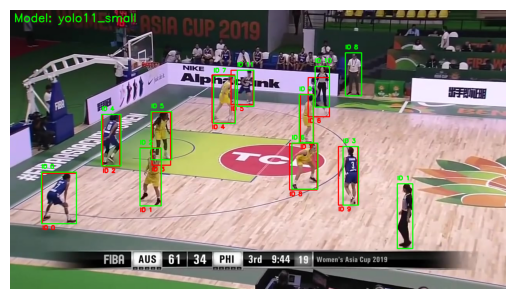

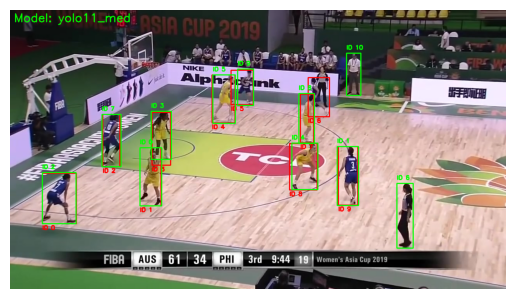

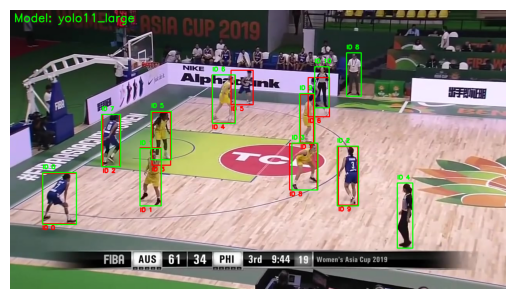

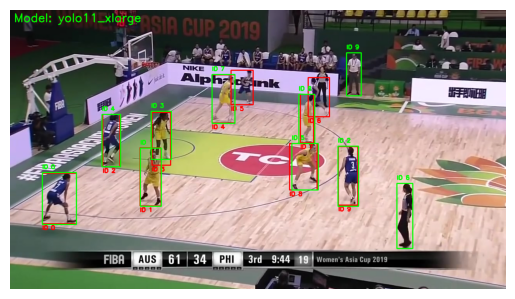

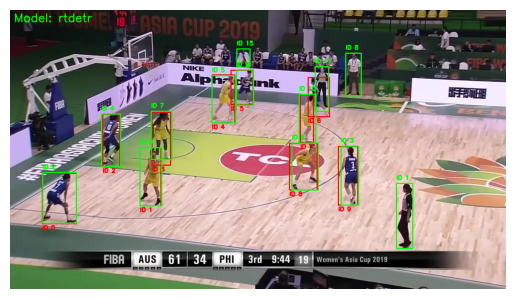

In [89]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

frame_gt = gt[gt[:, 0] == 1]
first_frame_results = {}
for model_name, model in models.items():
  first_frame_results[model_name] = model.predict(images[0], conf=0.5)[0]

# red = ground truth, green = predictions
for model_name, model_results in first_frame_results.items():
    img = np.array(images[0])
    cv2.putText(img, f"Model: {model_name}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

    for row in frame_gt:
        _, id, x, y, w, h = row[:6]
        x1, y1, x2, y2 = int(x), int(y), int(x + w), int(y + h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(img, f"ID {int(id)}", (x1, y2 + 15), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
    
    for i, box in enumerate(model_results.boxes):
        if int(box.cls[0]) != 0: # skip if class isn't person
            continue

        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        cv2.putText(img, f"ID {i}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        
    plt.imshow(img)
    plt.axis("off")
    plt.show()

### Matching Predictions to Ground Truth

- **IoU (Intersection over Union)** measures how much two boxes overlap: shared area divided by combined area, from 0 to 1.
- A prediction is a true positive (TP) if it matches a ground-truth box with IoU ≥ 0.5.
- Matching is one-to-one meaning each box can be matched only once, and the highest-overlap pairs are matched first.
- False positives (FP) are predictions that don't match ground truth. False negatives (FN) are unmatched ground-truth boxes.
- **Precision** = TP / (TP + FP): of the boxes the model drew, how many were real players.
- **Recall** = TP / (TP + FN): of the real players, how many the model found.

In [90]:
def iou(box_a, box_b):
    """Intersection over union for two (x1, y1, x2, y2) boxes."""
    inter_x1, inter_y1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    inter_x2, inter_y2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    intersection = max(0, inter_x2 - inter_x1) * max(0, inter_y2 - inter_y1)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    return intersection / (area_a + area_b - intersection)

def match_frame(pred_boxes, gt_boxes, iou_threshold=0.5):
    """One-to-one matching of predictions to ground truth for one frame."""
    candidate_pairs = []
    for pred_idx, pred_box in enumerate(pred_boxes):
        for gt_idx, gt_box in enumerate(gt_boxes):
            candidate_pairs.append((iou(pred_box, gt_box), pred_idx, gt_idx))
    candidate_pairs.sort(reverse=True)  # highest IoU first

    matched_preds, matched_gts, matches = set(), set(), []
    for score, pred_idx, gt_idx in candidate_pairs:
        if score < iou_threshold:
            break
        if pred_idx in matched_preds or gt_idx in matched_gts:
            continue
        matched_preds.add(pred_idx)
        matched_gts.add(gt_idx)
        matches.append((pred_idx, gt_idx, score))

    true_positives = len(matches)
    false_positives = len(pred_boxes) - true_positives
    false_negatives = len(gt_boxes) - true_positives
    return true_positives, false_positives, false_negatives, matches

### Evaluate All Models on the Sequence

Frames are run one at a time so the GPU doesn't run out of memory. Predictions below `conf=0.5` are dropped before matching.

In [ ]:
def run_model_on_frames(model, frames):
    """Run a model on each frame separately to keep memory usage low."""
    return [model.predict(frame, conf=0.5, verbose=False)[0] for frame in frames]

# Per-frame lists of (x1, y1, x2, y2) bounding boxes predicted for each model
predicted_boxes_by_model = {
    model_name: [
        [tuple(box.xyxy[0].tolist()) for box in frame_result.boxes if int(box.cls[0]) == 0]
        for frame_result in run_model_on_frames(model, images)
    ]
    for model_name, model in models.items()
}

# Per-frame lists of ground-truth boxes
ground_truth_boxes_by_frame = [
    [(row[2], row[3], row[2] + row[4], row[3] + row[5]) for row in gt[gt[:, 0] == frame_number]]
    for frame_number in range(1, len(images) + 1)
]

for model_name, predicted_boxes_per_frame in predicted_boxes_by_model.items():
    total_tp = total_fp = total_fn = 0
    for pred_boxes, gt_boxes in zip(predicted_boxes_per_frame, ground_truth_boxes_by_frame):
        tp, fp, fn, _ = match_frame(pred_boxes, gt_boxes)
        total_tp += tp
        total_fp += fp
        total_fn += fn

    precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0
    recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0
    print(f"{model_name}: TP={total_tp} FP={total_fp} FN={total_fn} "
          f"precision={precision:.3f} recall={recall:.3f}")

## Results

Here are the results when I ran on the full sequence of 825 frames, conf = 0.5, IoU ≥ 0.5.

Frames evaluated: **825**. Ground-truth boxes: **8,074**.

| Model | TP | FP | FN | Precision | Recall |
|---|---|---|---|---|---|
| YOLO11 nano | 5137 | 2050 | 2937 | 0.715 | 0.636 |
| YOLO11 small | 6415 | 2389 | 1659 | 0.729 | 0.795 |
| YOLO11 medium | 6162 | 1862 | 1912 | 0.768 | 0.763 |
| YOLO11 large | 6687 | 2158 | 1387 | 0.756 | 0.828 |
| YOLO11 xlarge | 6540 | 1771 | 1534 | 0.787 | 0.810 |
| RT-DETR-x | 7185 | 3029 | 889 | 0.703 | 0.890 |

Nano is clearly the weakest and misses about twice as many players as the others.

xlarge has the best precision and the most balanced YOLO results.

RT-DETR has the best recall but the most false positives. Many are likely people outside the playing area, such as referees, coaches, or spectators. Filtering boxes by whether the bottom-center point (the feet) falls inside a court polygon could cut false positives and raise precision with little effect on recall, since real players on the court would still pass.